### Turn 90 – Lösung Schritt für Schritt

*31. Bundeswettbewerb Informatik (2012), 1. Runde, Aufgabe 3*

Der Robotertyp „Turn90“ ist in seiner Bewegungsfähigkeit eingeschränkt: Er kann sich nur vorwärts bewegen und um 90 Grad drehen. Außerdem hat er keinerlei visuelle Sensoren, kann also nicht „sehen“. Seine Kontaktsensoren und auch seine Rechenfähigkeiten sind aber sehr ordentlich.

Ein neuer Auftrag zur Programmierung von Turn90-Robotern scheint darauf Rücksicht zu nehmen: Der Roboter soll befähigt werden, in einem Raum mit Hindernissen immer den einzigen Ausgang zu finden. Die Programmierer sind erleichtert, als sie hören, dass dem Raum ein Raster aus Quadraten zugrunde liegt. Die Wände füllen die äußeren Quadrate des Rasters, die Hindernisse füllen rechteckige Gruppen von Rasterquadraten aus. Der Roboter befindet sich zu Beginn in einem bestimmten Quadrat. Der Ausgang ist eine mindestens ein Quadrat breite Lücke in einer Raumwand.

#### Aufgabe 3

Schreibe ein Programm, mit dem ein Turn90-Roboter unter den genannten Bedingungen immer den Ausgang findet. Du kannst davon ausgehen, dass die Räume so gestaltet sind, dass es einen Weg vom Roboter zum Ausgang gibt. Schicke uns für die drei Räume, die auf den BwInf-Webseiten angegeben sind, und für zwei weitere Räume je ein grafisches Protokoll des Roboterweges. Lasse entweder dein Programm den Weg zeichnen, oder stelle ein schriftliches Protokoll des Weges selbst grafisch dar.

**Zu den Daten:** Die Dateien `raum0_beispiel.txt` (der Raum aus dem Aufgabenbild) und `raum1.txt` bis `raum3.txt` haben keine Formatbeschreibung. Wir lesen sie so: Zeile 1 Breite und Höhe des Rasters, Zeile 2 das Startfeld des Roboters, Zeile 3 der Ausgang als zwei Randfelder (`x1 y1 x2 y2`, die Lücke in der Wand), Zeile 4 die Anzahl der Hindernisse, dann je Hindernis zwei gegenüberliegende Eckfelder. Felder zählen ab 0, Hindernisse und Ausgang schließen die genannten Eckfelder ein. Probe: Mit dieser Lesart liegt der Roboter nie auf einem Hindernis, und in allen vier Räumen gibt es einen Weg zum Ausgang (das prüfen wir unten nach). In `eigene_testdaten/` liegen zwei weitere Räume im selben Format.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Online-Problem:** Der Roboter kennt den Raum nicht. Alle Wegsuchverfahren, die eine Karte brauchen (Breitensuche, A\*), scheiden aus. Er darf nur nach jedem Versuch weiterfahren zu erfahren, ob das Feld vor ihm frei war.
- **Linke-Hand-Regel:** Wer in einem Labyrinth immer mit einer Hand an der Wand bleibt, kommt an jede Stelle, die zur äußeren Wand gehört. Dazu braucht man keinen Speicher.
- **Pledge-Algorithmus:** Die Regel funktioniert nicht, wenn der Roboter an eine **frei stehende** Insel gerät: Er würde sie ewig umrunden. Der Pledge-Algorithmus zählt dazu die Drehungen mit und löst sich von der Insel, sobald er wieder in die ursprüngliche Richtung schaut.
- **Zustand und Schleifen:** Ein Verfahren ohne Gedächtnis wiederholt sich für immer, sobald derselbe Zustand (Feld und Blickrichtung) zum zweiten Mal vorkommt. So erkennen wir unten, dass die Linke-Hand-Regel allein scheitert.

**Nützliche Funktionen**
- `set` für schon gesehene Zustände (der Roboter selbst braucht es nicht, nur unsere Kontrolle).
- `random.Random(zahl)` für wiederholbare Zufallsräume.
- `matplotlib.pyplot` (`imshow`, `plot`) für das grafische Protokoll.

## Die Idee in Worten

**Was der Roboter kann.** Fünf Dinge, mehr nicht (so heißen sie auch in den Hinweisen):
- `fahre_vorwaerts()`: Versucht, ein Feld nach vorn zu fahren. Ist das Feld frei, fährt er und die Antwort ist `True`. Sonst bleibt er stehen (der Kontaktsensor meldet das Hindernis) und die Antwort ist `False`.
- `drehe_links()` und `drehe_rechts()`: um 90 Grad.
- `aktuelle_rotation()`: Wie oft hat er sich insgesamt gedreht? Links zählt +1, rechts −1, und zwar **absolut**: Vier Linksdrehungen ergeben 4, nicht 0.
- `am_ziel()`: Steht er auf dem Ausgang?

Der Roboter kennt weder seine Koordinaten noch den Plan des Raums.

**Das Verfahren.**
1. Fahre geradeaus, bis du auf etwas stößt. Merke dir die Rotation `r0`.
2. Drehe nach rechts (jetzt ist die linke Seite am Hindernis, wie eine Hand an der Wand) und fahre am Hindernis entlang: Ist links frei, biege links ab, sonst fahre geradeaus, sonst drehe nach rechts.
3. Sobald die Rotation wieder `r0` ist, schaut der Roboter wie zu Beginn in die ursprüngliche Richtung und löst sich vom Hindernis. Weiter bei 1.

Ist das Hindernis eine freie Insel, erreicht der Roboter `r0` wieder, sobald er um die Ecke des Hindernisses herum ist: Er fährt in der alten Richtung an der Insel vorbei. Folgt er dagegen der Außenwand (auch Hindernisse, die an der Wand hängen, gehören dazu), dreht er sich mit jeder Runde um 360 Grad nach rechts und die Rotation entfernt sich immer weiter von `r0`. Er löst sich nie von der Wand und kommt irgendwann am Ausgang vorbei. Die Hinweise sagen: Jedes Hindernis wird höchstens einmal umrundet, die Fahrzeit ist also proportional zur Zahl der freien Felder.

## Schritt 1: Den Raum einlesen

Ein Raum wird als Wörterbuch gespeichert. Die Felder, auf die der Roboter nicht darf, legen wir in einer Menge von Koordinatenpaaren ab: alle Randfelder außer den Feldern des Ausgangs, dazu alle Felder der Hindernisse. `x` zählt nach rechts, `y` nach oben.

In [ ]:
def lies_raum(dateiname):
    zahlen = []
    with open(dateiname, encoding='utf-8') as f:
        for zeile in f:
            if zeile.strip():
                zahlen.append([int(wort) for wort in zeile.split()])
    breite, hoehe = zahlen[0]
    anzahl = zahlen[3][0]
    return {'breite': breite, 'hoehe': hoehe, 'start': tuple(zahlen[1]),
            'ausgang': tuple(zahlen[2]), 'hindernisse': [tuple(z) for z in zahlen[4:4 + anzahl]]}


def felder_im_rechteck(x1, y1, x2, y2):
    """alle Felder des Rechtecks (Eckfelder eingeschlossen), egal in welcher Reihenfolge die Ecken stehen"""
    return {(x, y) for x in range(min(x1, x2), max(x1, x2) + 1)
                   for y in range(min(y1, y2), max(y1, y2) + 1)}


def ziel_felder(raum):
    return felder_im_rechteck(*raum['ausgang'])


def gesperrte_felder(raum):
    gesperrt = set()
    for x in range(raum['breite']):
        for y in range(raum['hoehe']):
            if x in (0, raum['breite'] - 1) or y in (0, raum['hoehe'] - 1):
                gesperrt.add((x, y))                     # Wand
    gesperrt -= ziel_felder(raum)                        # die Lücke im Ausgang ist frei
    for ecken in raum['hindernisse']:
        gesperrt |= felder_im_rechteck(*ecken)
    return gesperrt


raum0 = lies_raum('beispieldaten/raum0_beispiel.txt')
print(raum0)
print(len(gesperrte_felder(raum0)), 'gesperrte Felder,', len(ziel_felder(raum0)), 'Felder im Ausgang')

{'breite': 24, 'hoehe': 18, 'start': (11, 5), 'ausgang': (10, 17, 12, 17), 'hindernisse': [(4, 4, 6, 7), (7, 10, 15, 13), (18, 1, 20, 10)]}
155 gesperrte Felder, 3 Felder im Ausgang


## Schritt 2: Den Roboter simulieren

Weil wir keinen echten Roboter haben, bauen wir ihn nach. Die Simulation kennt den Raum, der **Roboter-Algorithmus** darf ihn aber nie benutzen: Er ruft nur die fünf Funktionen von oben auf. Damit wir es später prüfen können, steht der gesamte Zustand der Simulation im Wörterbuch `roboter`. Die Rotation 0 heißt „nach rechts“ (Richtung +x), +1 ist eine Linksdrehung, also nach oben (+y).

Zusätzlich zählt die Simulation Schritte, Drehungen und Zusammenstöße und merkt sich den Weg (Liste der Felder). Das braucht der Roboter nicht, es dient nur unserem Protokoll.

In [ ]:
RICHTUNGEN = [(1, 0), (0, 1), (-1, 0), (0, -1)]          # Rotation modulo 4: rechts, oben, links, unten

roboter = {}


def setze_roboter(raum):
    roboter.clear()
    roboter.update({'gesperrt': gesperrte_felder(raum), 'ziel': ziel_felder(raum), 'pos': raum['start'],
                    'rotation': 0, 'weg': [raum['start']], 'drehungen': 0, 'stoesse': 0})


def fahre_vorwaerts():
    dx, dy = RICHTUNGEN[roboter['rotation'] % 4]
    neu = (roboter['pos'][0] + dx, roboter['pos'][1] + dy)
    if neu in roboter['gesperrt']:
        roboter['stoesse'] += 1                          # Kontaktsensor meldet ein Hindernis
        return False
    roboter['pos'] = neu
    roboter['weg'].append(neu)
    return True


def drehe_links():
    roboter['rotation'] += 1
    roboter['drehungen'] += 1


def drehe_rechts():
    roboter['rotation'] -= 1
    roboter['drehungen'] += 1


def aktuelle_rotation():
    return roboter['rotation']


def am_ziel():
    return roboter['pos'] in roboter['ziel']


def schritte():
    """nur für unser Protokoll (der Roboter braucht es nicht): Anzahl der gefahrenen Felder"""
    return len(roboter['weg']) - 1


def position():
    """nur für unsere Kontrolle: Der Roboter selbst kennt seine Position nicht"""
    return roboter['pos']


setze_roboter(raum0)
print(fahre_vorwaerts(), roboter['pos'])                 # eins nach rechts
drehe_links()
print(aktuelle_rotation(), fahre_vorwaerts(), roboter['pos'])   # nach oben

True (12, 5)
1 True (12, 6)


## Schritt 3: Zeichnen

Das grafische Protokoll: Wände und Hindernisse dunkelgrau, der Ausgang grün, der Weg als blaue Linie durch die Mittelpunkte der Felder. Der Start ist ein Kreis, das Ende ein Quadrat. Die Zahlen auf der Achse sind die Koordinaten.

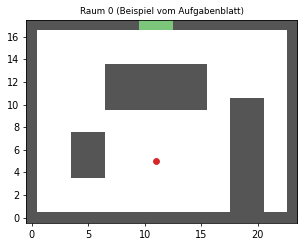

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def zeichne_raum(achse, raum, weg=None, titel=''):
    gesperrt = gesperrte_felder(raum)
    ziel = ziel_felder(raum)
    bild = []
    for y in range(raum['hoehe']):
        zeile = []
        for x in range(raum['breite']):
            if (x, y) in ziel:
                zeile.append(2)
            elif (x, y) in gesperrt:
                zeile.append(1)
            else:
                zeile.append(0)
        bild.append(zeile)
    achse.imshow(bild, origin='lower', cmap=ListedColormap(['white', '#555555', '#7bc67b']), vmin=0, vmax=2)
    if weg:
        achse.plot([p[0] for p in weg], [p[1] for p in weg], color='#1f5fbf', lw=1.2)
        achse.plot(weg[0][0], weg[0][1], 'o', color='#d62728', ms=6)
        achse.plot(weg[-1][0], weg[-1][1], 's', color='#d62728', ms=6)
    else:
        achse.plot(raum['start'][0], raum['start'][1], 'o', color='#d62728', ms=6)
    achse.set_title(titel, fontsize=9)


bild_fig, bild_achse = plt.subplots(figsize=(5, 4))
zeichne_raum(bild_achse, raum0, titel='Raum 0 (Beispiel vom Aufgabenblatt)')
plt.show()

Der Roboter (roter Kreis) steht etwas unterhalb der Mitte. Der Ausgang (grün) liegt oben in der Wand. Drei Hindernisse sind im Raum verteilt; das rechte reicht bis an die untere Wand.

## Schritt 4: Die Linke-Hand-Regel allein reicht nicht

Zuerst die naheliegende Idee, ohne Pledge: Der Roboter fährt zuerst geradeaus bis zur ersten Wand oder zum ersten Hindernis, dreht sich nach rechts (das Hindernis ist jetzt links) und folgt danach immer der Regel der Hinweise:
- Ist das Feld links frei, drehe nach links und fahre.
- Sonst, wenn das Feld vorn frei ist, fahre vorwärts.
- Sonst, wenn rechts frei ist, drehe nach rechts und fahre.
- Sonst kehre um.

`linke_hand_schritt` macht genau einen solchen Schritt. (Ohne die Fahrt geradeaus würde die Regel im freien Raum nur im Kreis fahren, weil dort links immer frei ist.) Der Roboter prüft „ist links frei“, indem er sich dorthin dreht und fährt. Klappt das nicht, dreht er zurück. Die Wiederholung `fahre_mit_linker_hand` ist die Kontrolle von außen: Merkt sie sich ein Paar (Feld, Richtung) zum zweiten Mal, wiederholt sich der Weg für immer, denn die Regel hat kein Gedächtnis.

In [ ]:
def linke_hand_schritt():
    drehe_links()
    if fahre_vorwaerts():              # links war frei
        return
    drehe_rechts()                     # zurück in die alte Richtung
    if fahre_vorwaerts():              # vorn war frei
        return
    drehe_rechts()
    if fahre_vorwaerts():              # rechts war frei
        return
    drehe_rechts()
    fahre_vorwaerts()                  # sonst umkehren


def fahre_mit_linker_hand():
    """True, wenn der Roboter den Ausgang erreicht, False, wenn sich sein Weg für immer wiederholt"""
    while not am_ziel() and fahre_vorwaerts():
        pass                           # zuerst geradeaus bis zur ersten Wand oder zum ersten Hindernis
    if am_ziel():
        return True
    drehe_rechts()                     # jetzt ist das Hindernis links
    gesehen = set()
    while not am_ziel():
        zustand = (position(), aktuelle_rotation() % 4)
        if zustand in gesehen:
            return False
        gesehen.add(zustand)
        linke_hand_schritt()
    return True


setze_roboter(raum0)
erfolg = fahre_mit_linker_hand()
print('Raum 0 erreicht den Ausgang:', erfolg, '- gefahrene Felder:', schritte())
linke_hand_weg0 = list(roboter['weg'])

Raum 0 erreicht den Ausgang: True - gefahrene Felder: 51


Im Beispielraum klappt die Regel: Der Roboter stößt zuerst auf das Hindernis rechts, das an der unteren Wand hängt, also faktisch zur Außenwand gehört, und folgt der Wand bis zum Ausgang. Wir lassen sie in allen sechs Räumen laufen (die vier Beispielräume und unsere zwei eigenen); die Räume lesen wir gleich für alle weiteren Schritte ein.

Raum 0          Ausgang erreicht: True
Raum 1          Ausgang erreicht: False
Raum 2          Ausgang erreicht: False
Raum 3          Ausgang erreicht: False
Raum 4 (eigen)  Ausgang erreicht: False
Raum 5 (eigen)  Ausgang erreicht: False


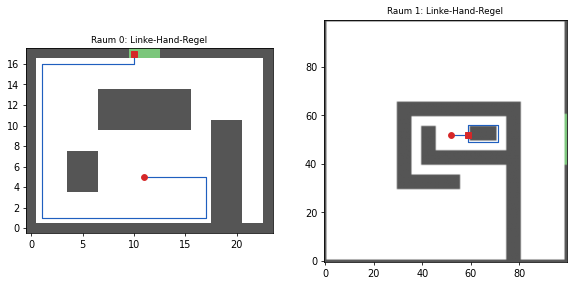

In [ ]:
RAUM_DATEIEN = [('Raum 0', 'beispieldaten/raum0_beispiel.txt'), ('Raum 1', 'beispieldaten/raum1.txt'),
                ('Raum 2', 'beispieldaten/raum2.txt'), ('Raum 3', 'beispieldaten/raum3.txt'),
                ('Raum 4 (eigen)', 'eigene_testdaten/raum4.txt'), ('Raum 5 (eigen)', 'eigene_testdaten/raum5.txt')]
raeume = [(name, lies_raum(datei)) for (name, datei) in RAUM_DATEIEN]

linke_hand_ergebnis = {}
for name, raum in raeume:
    setze_roboter(raum)
    linke_hand_ergebnis[name] = fahre_mit_linker_hand()
    print(f'{name:15} Ausgang erreicht: {linke_hand_ergebnis[name]}')

setze_roboter(raeume[1][1])
fahre_mit_linker_hand()
bild_fig, bild_achsen = plt.subplots(1, 2, figsize=(10, 4.5))
zeichne_raum(bild_achsen[0], raum0, linke_hand_weg0, 'Raum 0: Linke-Hand-Regel')
zeichne_raum(bild_achsen[1], raeume[1][1], roboter['weg'], 'Raum 1: Linke-Hand-Regel')
plt.show()

Nur in Raum 0 kommt die Linke-Hand-Regel ans Ziel, in den Räumen 1 bis 5 nicht. Das Bild von Raum 1 zeigt den Grund: Der Roboter fährt bis zum ersten Hindernis, hängt sich dort mit der linken Hand an und folgt ihm. Steht dieses Hindernis frei im Raum (hier das Rechteck rechts neben dem Start, Felder x 60 bis 70, y 50 bis 55), läuft er für immer im Kreis um diese Insel. Sein Weg wiederholt sich, er verlässt die Insel nie.

## Schritt 5: Der Pledge-Algorithmus

Jetzt der Algorithmus der Hinweise. Der Roboter fährt geradeaus, bis er stößt, merkt sich dann die Rotation `start_rotation`, dreht nach rechts und läuft am Hindernis entlang, **bis seine Rotation wieder `start_rotation` ist**. Dann schaut er wieder in die ursprüngliche Richtung und kann ohne Zusammenstoß mit demselben Hindernis geradeaus weiter.

Die Rotation zählt absolut. Nach dem Drehen nach rechts ist sie `start_rotation - 1`. Biegt der Roboter an einer Ecke der Insel nach links ab, ist sie wieder `start_rotation`, und er fährt in der alten Richtung weiter. Folgt er der Außenwand, sinkt sie bei jeder Runde um 4, kommt nie auf diesen Wert zurück und er bleibt an der Wand.

Raum 0: am Ziel: True | Felder gefahren: 51 | Drehungen: 91 | Zusammenstöße: 47
Weg: [(11, 5), (12, 5), (13, 5), (14, 5), (15, 5), (16, 5), (17, 5), (17, 4), (17, 3), (17, 2), (17, 1), (16, 1)] ...


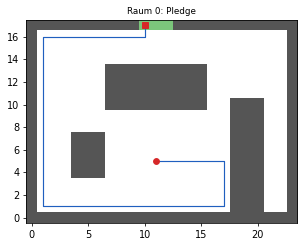

In [ ]:
def pledge():
    while not am_ziel():
        # 1. geradeaus bis zum Hindernis
        while not am_ziel() and fahre_vorwaerts():
            pass
        if am_ziel():
            return
        # 2. am Hindernis entlang, linke Hand an der Wand, bis die Rotation wieder die alte ist
        start_rotation = aktuelle_rotation()
        drehe_rechts()
        while not am_ziel() and aktuelle_rotation() != start_rotation:
            if fahre_vorwaerts():
                if am_ziel():              # Ausgang auch seitlich im Vorbeifahren erkennen
                    return
                drehe_links()              # Ecke? Dann ist links frei und wir fahren dorthin
                if not fahre_vorwaerts():
                    drehe_rechts()         # links war nicht frei, zurück in die Fahrtrichtung
            else:
                drehe_rechts()             # vorn blockiert: weiter an der Wand drehen


setze_roboter(raum0)
pledge()
print('Raum 0: am Ziel:', am_ziel(), '| Felder gefahren:', schritte(), '| Drehungen:', roboter['drehungen'],
      '| Zusammenstöße:', roboter['stoesse'])
print('Weg:', roboter['weg'][:12], '...')

bild_fig, bild_achse = plt.subplots(figsize=(5, 4))
zeichne_raum(bild_achse, raum0, roboter['weg'], 'Raum 0: Pledge')
plt.show()

Der Roboter fährt nach rechts bis zum Hindernis, das an der unteren Wand hängt, und folgt ihm und danach der Wand. Das Hindernis gehört zur Außenwand, also kommt die Rotation nie auf den alten Wert zurück, und er folgt der Wand bis zum Ausgang. Wie der Algorithmus Inseln umgeht, sieht man erst in den Räumen 1 bis 5 unten.

**Arbeitet `pledge` wirklich nur mit den fünf Roboterbefehlen?** Wir prüfen die Namen, die im Programmtext der Funktion vorkommen: Weder das Wörterbuch `roboter` noch Hilfsfunktionen der Simulation wie `position` tauchen darin auf.

In [ ]:
benutzte_namen = set(pledge.__code__.co_names)
print(sorted(benutzte_namen))
assert benutzte_namen == {'am_ziel', 'fahre_vorwaerts', 'aktuelle_rotation', 'drehe_rechts', 'drehe_links'}

['aktuelle_rotation', 'am_ziel', 'drehe_links', 'drehe_rechts', 'fahre_vorwaerts']


## Schritt 6: Alle Räume, grafisches Protokoll

Für die Kontrolle reicht „kommt er an?“ nicht. `pruefe_weg` prüft für jeden Weg, dass er auf dem Startfeld beginnt, dass je zwei aufeinander folgende Felder Nachbarn sind, dass kein Feld gesperrt ist, und dass er genau auf dem Ausgang endet (kein Feld davor liegt schon im Ausgang). Danach das Protokoll aller sechs Räume.

Raum              Felder  Schritte  Drehungen  Stöße  besuchte Felder
Raum 0              277        51         91     47               52
Raum 1             8329       469        822    413              470
Raum 2             7293       654       1070    536              627
Raum 3             8460       326        555    279              327
Raum 4 (eigen)      246        70         99     51               71
Raum 5 (eigen)      457        59         52     26               60


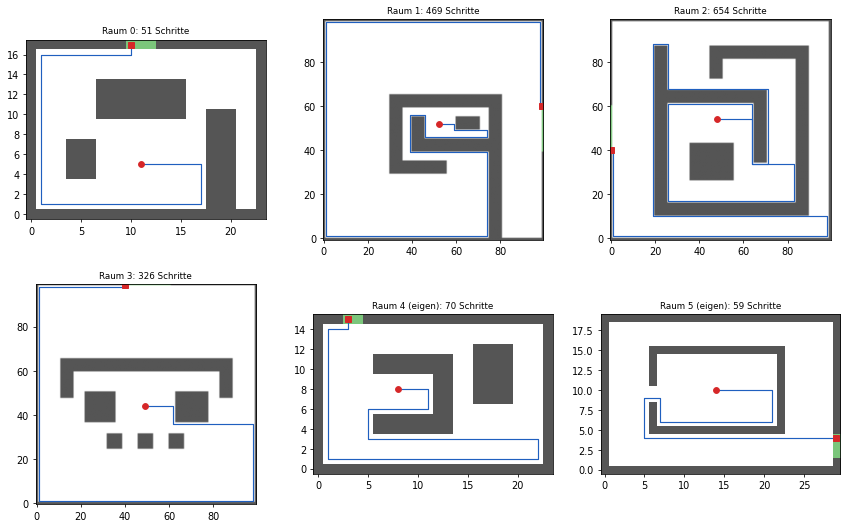

In [ ]:
def pruefe_weg(raum, weg):
    gesperrt = gesperrte_felder(raum)
    ziel = ziel_felder(raum)
    assert weg[0] == raum['start']
    for a, b in zip(weg, weg[1:]):
        assert abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1
    assert all(feld not in gesperrt for feld in weg)
    assert weg[-1] in ziel and all(feld not in ziel for feld in weg[:-1])


pledge_ergebnis = {}
print('Raum              Felder  Schritte  Drehungen  Stöße  besuchte Felder')
for name, raum in raeume:
    setze_roboter(raum)
    pledge()
    pruefe_weg(raum, roboter['weg'])
    frei = raum['breite'] * raum['hoehe'] - len(gesperrte_felder(raum))
    pledge_ergebnis[name] = {'frei': frei, 'schritte': schritte(), 'drehungen': roboter['drehungen'],
                             'stoesse': roboter['stoesse'], 'besucht': len(set(roboter['weg'])),
                             'weg': list(roboter['weg'])}
    e = pledge_ergebnis[name]
    print(f'{name:15} {frei:7} {e["schritte"]:9} {e["drehungen"]:10} {e["stoesse"]:6} {e["besucht"]:16}')

bild_fig, bild_achsen = plt.subplots(2, 3, figsize=(15, 9))
for achse, (name, raum) in zip(bild_achsen.flat, raeume):
    zeichne_raum(achse, raum, pledge_ergebnis[name]['weg'], f'{name}: {pledge_ergebnis[name]["schritte"]} Schritte')
plt.show()

Alle sechs Wege sind gültig: Der Roboter beginnt am Startfeld, fährt nur über freie Felder und endet auf dem Ausgang. Die Zahlen:

- Die Spalte „Felder“ sind die freien Felder des Raums (ohne Wände und Hindernisse; der Ausgang zählt dazu).
- „Stöße“ sind die Versuche, in ein gesperrtes Feld zu fahren. Der Kontaktsensor liefert sie dem Roboter gratis.
- Die Zahl der Schritte ist in allen Räumen deutlich kleiner als die Zahl der freien Felder. Das ist nicht überraschend: Der Roboter muss nicht alles besuchen, nur bis zum Ausgang kommen.
- Die Zahl der besuchten Felder ist fast so groß wie die der Schritte: Der Roboter kommt kaum zweimal auf dasselbe Feld.

## Schritt 7: Wie gut ist der Weg?

Zum Vergleich berechnen wir mit Breitensuche den kürzesten Weg, den man **mit Karte** fände. Der Roboter darf diese Karte nicht benutzen; es geht nur darum zu sehen, was die Blindheit kostet.

In [ ]:
from collections import deque


def kuerzester_weg(raum):
    """Länge des kürzesten Wegs vom Start zum Ausgang (Breitensuche mit Karte), None wenn es keinen gibt"""
    gesperrt = gesperrte_felder(raum)
    ziel = ziel_felder(raum)
    abstand = {raum['start']: 0}
    schlange = deque([raum['start']])
    while schlange:
        x, y = schlange.popleft()
        if (x, y) in ziel:
            return abstand[(x, y)]
        for dx, dy in RICHTUNGEN:
            nachbar = (x + dx, y + dy)
            if nachbar not in gesperrt and nachbar not in abstand:
                abstand[nachbar] = abstand[(x, y)] + 1
                schlange.append(nachbar)
    return None


print('Raum              Pledge  kürzester Weg  Verhältnis')
kuerzeste = {}
for name, raum in raeume:
    kuerzeste[name] = kuerzester_weg(raum)
    s = pledge_ergebnis[name]['schritte']
    print(f'{name:15} {s:8} {kuerzeste[name]:14} {s / kuerzeste[name]:11.1f}')

Raum              Pledge  kürzester Weg  Verhältnis
Raum 0                51             21         2.4
Raum 1               469            201         2.3
Raum 2               654            196         3.3
Raum 3               326            132         2.5
Raum 4 (eigen)        70             11         6.4
Raum 5 (eigen)        59             39         1.5


Der Pledge-Weg ist in den vier Beispielräumen 2,3- bis 3,3-mal so lang wie der kürzeste, in unserem Raum 4 (die U-förmige Falle, in der der Roboter erst auf die Rückwand fährt) sogar 6,4-mal, in Raum 5 nur 1,5-mal. Das ist der Preis dafür, dass der Roboter den Raum nicht kennt: Er läuft an Hindernissen entlang, auch wenn der Ausgang auf der anderen Seite liegt. Wichtig ist, dass er den Ausgang **sicher** findet, nicht dass er schnell ist.

## Schritt 8: Zufällige Räume als Gegenprobe

Sechs Räume sind wenig. Wir erzeugen 500 zufällige Räume (Größe 12 bis 30, drei bis zehn Rechtecke, Ausgang an einer zufälligen Wand), behalten die, in denen es einen Weg zum Ausgang gibt (Breitensuche), und lassen drei Verfahren laufen:
1. **Linke-Hand-Regel allein** (mit Erkennung von Wiederholungen).
2. **Pledge** wie oben.
3. **Pledge mit falsch gezählter Rotation:** Die Hinweise warnen, die Ausrichtung dürfe nicht nur modulo 360 Grad gezählt werden. Diese Variante vergleicht `aktuelle_rotation() % 4` mit `start_rotation % 4` und löst sich damit nach einer einzigen Drehung um 360 Grad von der Wand. Weil sie sich in einer Schleife verfangen kann, bekommt sie eine Obergrenze von 5000 Schritten.

In [ ]:
import random


def pledge_modulo(max_schritte):
    while not am_ziel() and schritte() < max_schritte:
        while not am_ziel() and schritte() < max_schritte and fahre_vorwaerts():
            pass
        if am_ziel():
            return
        start_rotation = aktuelle_rotation()
        drehe_rechts()
        while not am_ziel() and schritte() < max_schritte and (aktuelle_rotation() - start_rotation) % 4 != 0:
            if fahre_vorwaerts():
                if am_ziel():
                    return
                drehe_links()
                if not fahre_vorwaerts():
                    drehe_rechts()
            else:
                drehe_rechts()


def zufallsraum(zufall):
    breite = zufall.randint(12, 30)
    hoehe = zufall.randint(12, 30)
    hindernisse = []
    for _ in range(zufall.randint(3, 10)):
        x1 = zufall.randint(1, breite - 3)
        y1 = zufall.randint(1, hoehe - 3)
        x2 = min(breite - 2, x1 + zufall.randint(0, breite // 2))
        y2 = min(hoehe - 2, y1 + zufall.randint(0, hoehe // 2))
        hindernisse.append((x1, y1, x2, y2))
    seite = zufall.randint(0, 3)
    a = zufall.randint(1, min(breite, hoehe) - 3)
    ausgang = [(a, 0, a + 1, 0), (a, hoehe - 1, a + 1, hoehe - 1), (0, a, 0, a + 1), (breite - 1, a, breite - 1, a + 1)][seite]
    raum = {'breite': breite, 'hoehe': hoehe, 'start': (0, 0), 'ausgang': ausgang, 'hindernisse': hindernisse}
    freie = [(x, y) for x in range(1, breite - 1) for y in range(1, hoehe - 1) if (x, y) not in gesperrte_felder(raum)]
    if not freie:
        return None
    raum['start'] = zufall.choice(freie)
    return raum


zufall = random.Random(1)
anzahl = {'Raeume': 0, 'Linke Hand': 0, 'Pledge': 0, 'Pledge modulo 4': 0}
laengster_verhaeltnis = 0
modulo_beispiel = None
for _ in range(500):
    raum = zufallsraum(zufall)
    if raum is None or kuerzester_weg(raum) is None:
        continue
    anzahl['Raeume'] += 1
    frei = raum['breite'] * raum['hoehe'] - len(gesperrte_felder(raum))
    setze_roboter(raum)
    anzahl['Linke Hand'] += fahre_mit_linker_hand()
    setze_roboter(raum)
    pledge()
    pruefe_weg(raum, roboter['weg'])
    anzahl['Pledge'] += 1
    laengster_verhaeltnis = max(laengster_verhaeltnis, schritte() / frei)
    setze_roboter(raum)
    pledge_modulo(5000)
    if am_ziel():
        anzahl['Pledge modulo 4'] += 1
    elif modulo_beispiel is None and raum['breite'] * raum['hoehe'] <= 400:
        modulo_beispiel = (raum, list(roboter['weg'][:400]))

for verfahren in anzahl:
    print(f'{verfahren:16} {anzahl[verfahren]}')
print('größtes Verhältnis Schritte / freie Felder bei Pledge:', round(laengster_verhaeltnis, 2))

Raeume           350
Linke Hand       327
Pledge           350
Pledge modulo 4  276
größtes Verhältnis Schritte / freie Felder bei Pledge: 1.05


Pledge hat in **allen** 350 Räumen den Ausgang gefunden; das Wegprotokoll war jedes Mal gültig. Die Linke-Hand-Regel allein schafft 327 der 350 Räume: In den meisten Zufallsräumen trifft der Roboter zuerst auf die Außenwand oder ein Hindernis an der Wand. In den übrigen 23 liegt eine Insel im Weg. Die Variante mit der nur modulo 4 gezählten Rotation schafft 276 Räume, scheitert also in 74 Räumen, deutlich öfter als die Linke-Hand-Regel allein: Sie verlässt Wand und Hindernis schon bei einer vollen Drehung (360 Grad) um sich selbst und gerät dabei in eine Schleife. Das ist die Warnung der Hinweise, dass die Ausrichtung **absolut** gezählt werden muss.

Und die Fahrzeit? Bei allen Zufallsräumen lag die Schrittzahl höchstens bei dem 1,05-Fachen der Zahl der freien Felder (das größte Verhältnis steht oben). Das passt zu den Hinweisen: Die Fahrzeit wächst linear mit der Zahl `N` der freien Felder, weil jedes Hindernis höchstens einmal umrundet wird. (Das ist eine Messung an Zufallsräumen, kein Beweis.)

So sieht ein Raum aus, in dem die Variante mit der modulo-Zählung hängen bleibt (die ersten 400 Felder ihres Weges):

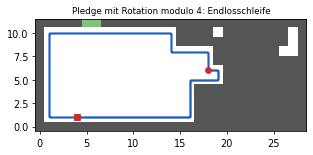

In [ ]:
bild_fig, bild_achse = plt.subplots(figsize=(5, 4.5))
zeichne_raum(bild_achse, modulo_beispiel[0], modulo_beispiel[1], 'Pledge mit Rotation modulo 4: Endlosschleife')
plt.show()

## Für Neugierige

- **Weg und Gedächtnis:** Der Roboter braucht nur eine einzige Zahl, die gemerkte Rotation `start_rotation`, und die aktuelle Rotation (Speicher `O(1)`). Die Alternative der Hinweise merkt sich alle besuchten Felder am Hindernis (Speicher `O(N)`) und fährt zum besten Punkt zurück. Und die einfachste Idee, eine Karte aufzubauen und nach jedem unbekannten Hindernis neu zu planen, hat Fahrzeit `O(N²)`.
- **Der erste Schritt in den Hinweisen:** Der Pseudocode beginnt mit „gehe zum linken Rasterquadrat, falls frei“, damit der Roboter zuerst auf ein Hindernis der Außenwand trifft. Unser Verfahren läuft stattdessen gleich geradeaus. Beides findet den Ausgang, die Wege sind nur verschieden.
- **Unlösbare Räume:** Die Aufgabe garantiert einen Weg. Gäbe es keinen, würde der Roboter ewig laufen. Mit einer Kontrolle von außen wie bei der Linken-Hand-Regel (Zustand wiederholt sich) könnte man das erkennen, nur kennt der Roboter selbst seine Position nicht.
- **Mit Kompass:** Hätte der Roboter Koordinaten, könnte er sich eine Karte merken. Das wäre schon die „weitere, noch schlechtere Lösung“ der Hinweise.

## Zum Schluss: Geht das mit MiniZinc?

**Die Aufgabe selbst nicht.** MiniZinc sucht eine Lösung, wenn man **alle Daten kennt**. Der Roboter kennt aber die Karte nicht, er entdeckt sie erst beim Fahren. Ein MiniZinc-Modell des Raums dürfte der Roboter gar nicht benutzen (die Bewertungskriterien verlangen ausdrücklich, dass er nur erlaubte Informationen nutzt). Das Pledge-Verfahren ist eine Regel, die Schritt für Schritt entscheidet, und keine Optimierungsaufgabe.

**Der Vergleichsweg (kürzester Weg mit Karte).** Man könnte MiniZinc höchstens dafür nehmen, was wir in Schritt 7 mit der Breitensuche gerechnet haben: den kürzesten Weg mit bekannter Karte. Das Modell dazu: Für die Zeitpunkte `0..T` gibt es Variablen `x[t]`, `y[t]`, die Position nach `t` Schritten. Sie startet auf dem Startfeld, liegt immer auf einem freien Feld, bewegt sich pro Zeitpunkt um höchstens ein Feld und endet auf dem Ausgang; minimiert wird die Zahl der Bewegungen. Als Obergrenze `T` haben wir die Schrittzahl des Pledge-Wegs genommen.

```minizinc
int: B; int: H; int: T; int: sx; int: sy;
array[0..B-1, 0..H-1] of 0..1: blockiert;       % 1 = Wand oder Hindernis
array[0..B-1, 0..H-1] of 0..1: ziel;            % 1 = Feld des Ausgangs
array[0..T] of var 0..B-1: x;
array[0..T] of var 0..H-1: y;
constraint x[0] = sx;
constraint y[0] = sy;
constraint forall(t in 0..T)(blockiert[x[t], y[t]] = 0);
constraint forall(t in 0..T-1)(abs(x[t+1] - x[t]) + abs(y[t+1] - y[t]) <= 1);
constraint ziel[x[T], y[T]] = 1;
var int: laenge = sum(t in 0..T-1)(abs(x[t+1] - x[t]) + abs(y[t+1] - y[t]));
solve minimize laenge;
```

Die Datendatei (`.dzn`) mit den beiden Feldern `blockiert` und `ziel` entsteht aus den Mengen `gesperrte_felder` und `ziel_felder` (ein `array2d`).

**Messung** (Gecode, Chuffed; Zeitlimit 60 Sekunden je Lauf, `T` = Schritte des Pledge-Wegs). Das Modell ist hier **nicht geeignet**:

| Raum | `T` | kürzester Weg (Breitensuche) | Gecode | Chuffed |
|---|---|---|---|---|
| Raum 0 | 51 | 21 | 37 nach 60 s, Optimum nicht bewiesen | 36 nach 60 s, Optimum nicht bewiesen |
| Raum 1 | 469 | 201 | nach 60 s keine Lösung | Fehler nach über vier Minuten |
| Raum 2, Raum 3 | 654, 326 | 196, 132 | in 100 s keine Ausgabe | nicht mehr versucht |

Schon beim kleinsten Raum (24 × 18 Felder) beweist keiner der beiden Solver in einer Minute das Optimum, das die Breitensuche in Bruchteilen einer Sekunde findet. Der Grund: Das Modell wählt eine Folge von Positionen mit Tabellenzugriffen und weiß nichts von der Gitterstruktur, die Breitensuche nutzt. Für Wegsuche in Gittern sind Graphalgorithmen das richtige Werkzeug, MiniZinc bringt hier nichts. Deshalb nehmen wir MiniZinc in dieses Notebook nicht als Lösung auf. (Die Zahlen sind einmalige Messungen auf unserem Rechner und nicht als Modell im Notebook ausführbar, MiniZinc läuft nicht im Browser.)